# Comparing Pyro to Numpyro

This notebook compares [Pyro](https://pyro.ai/) and [NumPyro](https://num.pyro.ai/en/stable/) for estimating a Bayesian neural network via HMC/NUTS. These packages have very similar frontends. Pyro is built on PyTorch, and NumPyro is built on Numpy/JAX.

Both packages produce the same posterior estimates, but NumPyro is much faster. NumPyro's current release is considered in beta, so its exact interface is subject to change.

## Training Data

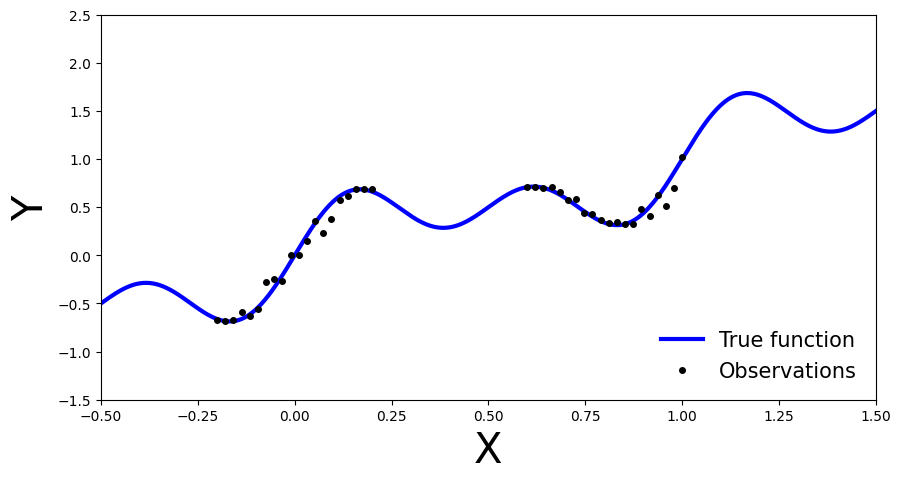

In [1]:
import math
import numpy as np
import matplotlib.pyplot as plt

# Set random seed for reproducibility
np.random.seed(42)

nobs = 40

# Generate data
x_obs = np.hstack([np.linspace(-0.2, 0.2, nobs // 2), np.linspace(0.6, 1, nobs // 2)])
noise = 0.02 * np.random.randn(x_obs.shape[0])
y_obs = x_obs + 0.3 * np.sin(2 * np.pi * (x_obs + noise)) + 0.3 * np.sin(4 * np.pi * (x_obs + noise)) + noise

x_true = np.linspace(-0.5, 1.5, 1000)
y_true = x_true + 0.3 * np.sin(2 * np.pi * x_true) + 0.3 * np.sin(4 * np.pi * x_true)

# Set plot limits and labels
xlims = [-0.5, 1.5]
ylims = [-1.5, 2.5]

# Create plot
fig, ax = plt.subplots(figsize=(10, 5))
ax.plot(x_true, y_true, 'b-', linewidth=3, label="True function")
ax.plot(x_obs, y_obs, 'ko', markersize=4, label="Observations")
ax.set_xlim(xlims)
ax.set_ylim(ylims)
ax.set_xlabel("X", fontsize=30)
ax.set_ylabel("Y", fontsize=30)
ax.legend(loc=4, fontsize=15, frameon=False)

plt.show()

In [2]:
from time import perf_counter as timer

In [3]:
def plot_predictions(X_train, Y_train, X_true, Y_true, Y_pred):
    fig, ax = plt.subplots()
    xlims = [X_true.min(), X_true.max()]
    ylims = [Y_true.min(), Y_true.max()]
    ybuff = 0.1 * (ylims[1] - ylims[0])
    ylims[0] -= ybuff
    ylims[1] += ybuff
    plt.xlim(xlims)
    plt.ylim(ylims)
    plt.xlabel("X", fontsize=20)
    plt.ylabel("Y", fontsize=20)
    # Observations on top
    ax.plot(X_train.squeeze(), Y_train.squeeze(), 'ko', markersize=4, label="observations", zorder = 20)
    # True function underneath
    ax.plot(X_true.squeeze(), Y_true.squeeze(), 'b-', linewidth=3, label = "true function", zorder = 10)
    # Predicted functions underneath
    for i in range(Y_pred.shape[0]):
        Y_inst = Y_pred[i].squeeze()
        label = "posterior predictions" if i == 0 else None
        ax.plot(X_true, Y_inst, "r-", linewidth=0.5, alpha=0.5, label = label, zorder=0)
    plt.legend(loc = "lower right")

## Global Network Parameters

In [4]:
width = 1000
tanhscale = 2.0

## Pyro

In [5]:
import pyro
import pyro.distributions as pdist
import pyro.infer as pinfer
from torch.nn.functional import tanh as ttanh
import torch

print(pyro.__version__)
torch.set_default_device("cpu")


1.9.1


In [6]:
x_train_torch = torch.tensor(x_obs).float().reshape((-1,1))
y_train_torch = torch.tensor(y_obs).float().reshape((-1,1))
x_true_torch = torch.tensor(x_true).float().reshape((-1,1))

The test model will be a neural network with two hidden layers and tanh activation functions.

In [7]:
def pyro_model(X, Y=None):
    assert X.ndim == 2
    assert (Y is None) or (Y.ndim == 2)
    assert (Y is None) or (X.shape[0] == Y.shape[0])

    n_feat = X.shape[1]
    n_out = X.shape[1]
    n_obs = X.shape[0]

    weight_in = pyro.sample("weight_in", pdist.Normal(0,1).expand((n_feat, width)).to_event(2))
    bias_in = pyro.sample("bias_in", pdist.Normal(0,1).expand((width,)).to_event(1))

    weight_mid = pyro.sample("weight_mid", pdist.Normal(0, 1 / math.sqrt(width)).expand((width, width)).to_event(2))
    bias_mid = pyro.sample("bias_mid", pdist.Normal(0, 1).expand((width,)).to_event(1))\
    
    weight_out = pyro.sample("weight_out", pdist.Normal(0, 1 / math.sqrt(width)).expand((width, n_out)).to_event(2))
    bias_out = pyro.sample("bias_out", pdist.Normal(0, 1).expand((n_out,)).to_event(1))
    
    sigma = pyro.sample("sigma", pdist.HalfNormal(0.1))

    with pyro.plate("data", n_obs, dim = -1):
        mu = pyro.deterministic(
            "mu", 
            ttanh(tanhscale * (ttanh(tanhscale * (X @ weight_in + bias_in)) @ weight_mid + bias_mid)) @ weight_out + bias_out, 
            event_dim = 1
        )
        obs = pyro.sample("obs", pdist.Normal(mu, sigma).to_event(1), obs = Y)

    return obs


In [ ]:
pyro.set_rng_seed(2024)

pyro_nuts = pinfer.NUTS(pyro_model)
pyro_mcmc = pinfer.MCMC(pyro_nuts, num_samples = 100, warmup_steps = 100)

start = timer()
pyro_mcmc.run(x_train_torch, y_train_torch)
end = timer()

print(f"Elapsed time: {end - start}")

In [ ]:
pyro_pred = pinfer.Predictive(pyro_model, pyro_mcmc.get_samples())(x_true_torch)

plot_predictions(x_train_torch, y_train_torch, x_true, y_true, pyro_pred["mu"])

print(pyro_mcmc.get_samples()['sigma'].mean())

### Pyro - JIT compiled

Pyro's NUTS implementation has the option to JIT compile the model, which speeds up computation slightly.

In [ ]:
pyro.set_rng_seed(2024)

pyro_nuts_jit = pinfer.NUTS(pyro_model, jit_compile = True)
pyro_mcmc_jit = pinfer.MCMC(pyro_nuts_jit, num_samples = 100, warmup_steps = 100)

start = timer()
pyro_mcmc_jit.run(x_train_torch, y_train_torch)
end = timer()

print(f"Elapsed time: {end - start}")

In [ ]:
pyro_pred_jit = pinfer.Predictive(pyro_model, pyro_mcmc_jit.get_samples())(x_true_torch)

plot_predictions(x_train_torch, y_train_torch, x_true, y_true, pyro_pred_jit["mu"])

print(pyro_mcmc_jit.get_samples()['sigma'].mean())

## NumPyro

Notice the similarity of the NumPyro model to the Pyro model, with a few small differences in the NumPyro interface. Most noticeably, NumPyro sampling methods need a random number seed argument. Data is also numpy arrays rather than Torch tensors.

The NumPyro sampler takes about 7% of the time of even the JIT compiled Pyro sampler. The Pyro website claims a 100x speedup of NumPyro over Pyro for HMC/NUTS.

In [8]:
import numpyro
import numpyro.distributions as npdist
import numpyro.infer as npinfer
import jax.numpy as jnp
from jax import random
import jax

print(numpyro.__version__)
numpyro.set_platform("cpu")

0.15.1


In [9]:
x_train_np = jnp.array(x_train_torch)
y_train_np = jnp.array(y_train_torch)
x_true_np = jnp.array(x_true_torch)

In [10]:
def numpyro_model(X, Y=None):
    assert X.ndim == 2
    assert (Y is None) or (Y.ndim == 2)
    assert (Y is None) or (X.shape[0] == Y.shape[0])

    n_feat = X.shape[1]
    n_out = X.shape[1]
    n_obs = X.shape[0]

    weight_in = numpyro.sample("weight_in", npdist.Normal(0,1).expand((n_feat, width)).to_event(2))
    bias_in = numpyro.sample("bias_in", npdist.Normal(0,1).expand((width,)).to_event(1))

    weight_mid = numpyro.sample("weight_mid", npdist.Normal(0, 1 / math.sqrt(width)).expand((width, width)).to_event(2))
    bias_mid = numpyro.sample("bias_mid", npdist.Normal(0, 1).expand((width,)).to_event(1))\
    
    weight_out = numpyro.sample("weight_out", npdist.Normal(0, 1 / math.sqrt(width)).expand((width, n_out)).to_event(2))
    bias_out = numpyro.sample("bias_out", npdist.Normal(0, 1).expand((n_out,)).to_event(1))
    
    sigma = numpyro.sample("sigma", npdist.HalfNormal(0.1))

    mu = numpyro.deterministic(
        "mu", 
        jnp.tanh(tanhscale * (jnp.tanh(tanhscale * (X @ weight_in + bias_in)) @ weight_mid + bias_mid)) @ weight_out + bias_out
    )

    with numpyro.plate("data", n_obs, dim = -1):
        obs = numpyro.sample("obs", npdist.Normal(mu, sigma).to_event(1), obs=Y)
    
    return obs

In [ ]:
rng = random.PRNGKey(2024)

numpyro_nuts = npinfer.NUTS(numpyro_model)
numpyro_mcmc = npinfer.MCMC(numpyro_nuts, num_warmup = 100, num_samples = 100)

start = timer()
numpyro_mcmc.run(rng, x_train_np, y_train_np)
end = timer()

print(f"Elapsed time: {end - start}")

In [ ]:
numpyro_pred = npinfer.Predictive(numpyro_model, numpyro_mcmc.get_samples(), return_sites=['mu'])(rng, x_true_np)

plot_predictions(x_train_np, y_train_np, x_true, y_true, numpyro_pred["mu"])

print(numpyro_mcmc.get_samples()['sigma'].mean())

# GPU-based sampling

## Pyro

In [12]:
with torch.device("cuda:3"):
    x_train_torch_gpu = torch.tensor(x_obs).float().reshape((-1,1))
    y_train_torch_gpu = torch.tensor(y_obs).float().reshape((-1,1))
    x_true_torch_gpu = torch.tensor(x_true).float().reshape((-1,1))


In [ ]:
with torch.device("cuda:3"):
    pyro.set_rng_seed(2024)

    pyro_gpu_nuts = pinfer.NUTS(pyro_model)
    pyro_gpu_mcmc = pinfer.MCMC(pyro_gpu_nuts, num_samples = 100, warmup_steps = 100)

    start = timer()
    pyro_gpu_mcmc.run(x_train_torch_gpu, y_train_torch_gpu)
    end = timer()

print(f"Elapsed time: {end - start}")

In [ ]:
with torch.device("cuda:3"):
    pyro_pred_gpu = pinfer.Predictive(pyro_model, pyro_gpu_mcmc.get_samples())(x_true_torch_gpu)

plot_predictions(x_train_torch, y_train_torch, x_true, y_true, pyro_pred_gpu["mu"].cpu())

print(pyro_gpu_mcmc.get_samples()['sigma'].mean())

### Pyro - JIT

In [17]:
with torch.device("cuda:3"):
    pyro.set_rng_seed(2024)

    pyro_gpu_nuts_jit = pinfer.NUTS(pyro_model, jit_compile = True)
    pyro_gpu_mcmc_jit = pinfer.MCMC(pyro_gpu_nuts_jit, num_samples = 100, warmup_steps = 100)

    start = timer()
    pyro_gpu_mcmc_jit.run(x_train_torch_gpu, y_train_torch_gpu)
    end = timer()

print(f"Elapsed time: {end - start}")

Sample: 100%|██████████| 200/200 [02:09,  1.55it/s, step size=1.50e-02, acc. prob=0.922]

Elapsed time: 129.23785091703758


tensor(0.1399, device='cuda:3')


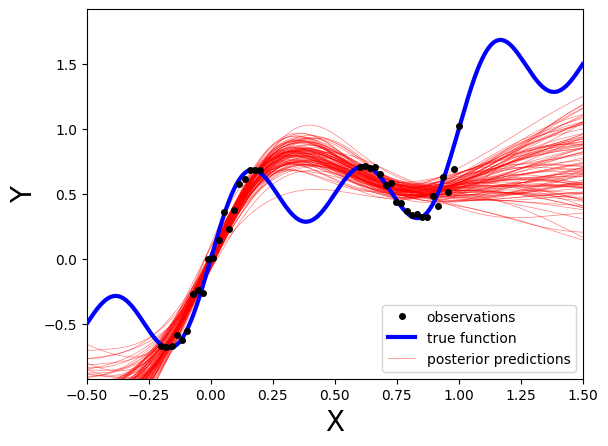

In [18]:
with torch.device("cuda:3"):
    pyro_pred_gpu_jit = pinfer.Predictive(pyro_model, pyro_gpu_mcmc_jit.get_samples())(x_true_torch_gpu)

plot_predictions(x_train_torch, y_train_torch, x_true, y_true, pyro_pred_gpu_jit["mu"].cpu())

print(pyro_gpu_mcmc_jit.get_samples()['sigma'].mean())

## NumPyro

In [19]:
import jax

with jax.default_device(jax.devices("gpu")[3]):
    x_train_np_gpu = jnp.array(x_train_torch)
    y_train_np_gpu = jnp.array(y_train_torch)
    x_true_np_gpu = jnp.array(x_true_torch)

    rng = random.PRNGKey(2024)

    numpyro_nuts_gpu = npinfer.NUTS(numpyro_model)
    numpyro_mcmc_gpu = npinfer.MCMC(numpyro_nuts_gpu, num_warmup = 100, num_samples = 100)

    start = timer()
    numpyro_mcmc_gpu.run(rng, x_train_np_gpu, y_train_np_gpu)
    end = timer()

print(f"Elapsed time: {end - start}")

sample: 100%|██████████| 200/200 [00:26<00:00,  7.68it/s, 255 steps of size 1.98e-02. acc. prob=0.90]


Elapsed time: 26.36354069970548


0.13871859


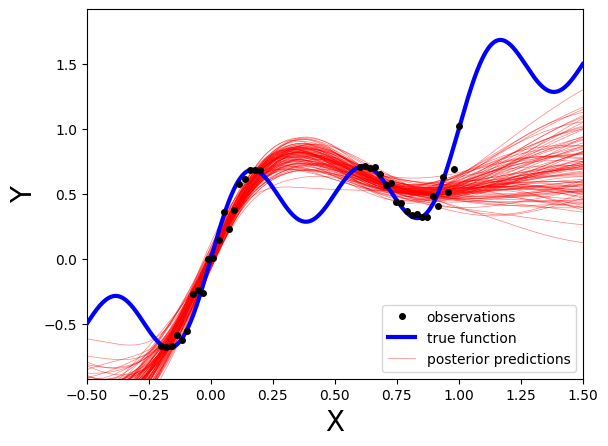

In [20]:
numpyro_pred_gpu = npinfer.Predictive(numpyro_model, numpyro_mcmc_gpu.get_samples(), return_sites=['mu'])(rng, x_true_np_gpu)

plot_predictions(x_train_np, y_train_np, x_true, y_true, numpyro_pred_gpu["mu"])

print(numpyro_mcmc_gpu.get_samples()['sigma'].mean())